<a href="https://colab.research.google.com/github/wldanzahrr/Analisis_Volume_Lambung_Kapal/blob/main/2508301002_Muhammad_Wildan_Zahir_ANUM_Volume_Kapal_kotak_45cm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nama   : Muhammad Wildan Zahir
# NPM    : 25083010002
# Mata Kuliah : Analisis Numerik
# kelas  : A

Link Github : https://github.com/wldanzahrr/Analisis_Volume_Lambung_Kapal


# PERHITUNGAN VOLUME LAMBUNG KAPAL

Ketentuan Dari Soal :
- 1 dash kosong = 5+5 = 10
- Lantai kapal datar (tanpa keel) -> tampak depan semuanya persegi panjang
- Volume reserve buoyancy tidak dihitung
- Ukuran satu kotak dari 10 cm menjadi 45 cm


**Cara Kerja** :    
1. Membagi lambung kapal menjadi beberapa stasiun
Lambung kapal dibagi menjadi beberapa stasiun atau irisan melintang dengan jarak Δx = 45 cm, sesuai dengan skala pada gambar.

2. Menentukan ukuran pada setiap stasiun
Pada setiap stasiun, ditentukan lebar lambung berdasarkan tampak atas dan tinggi lambung berdasarkan tampak samping.

3. Menghitung luas penampang setiap stasiun
Karena lantai kapal dianggap datar dan tidak memiliki keel, maka penampang depan dianggap berbentuk persegi panjang. Luas setiap penampang dihitung dengan:
$A_i = \text{lebar} \times \text{tinggi}$

4. Menghitung volume satu lambung dengan metode trapesium
Nilai luas penampang pada setiap stasiun kemudian diintegralkan sepanjang kapal menggunakan metode trapesium:

$$V = \Delta x \left[ 2A_0 + D_{an} + \sum_{i=1}^{n-1} A_i \right]$$


5. Menghitung volume satu lambung dengan metode Simpson 1/3
Perhitungan volume juga dilakukan menggunakan metode Simpson 1/3 sebagai pembanding:
$$V = \frac{\Delta x}{3} \left[ A_0 + D_{an} + 4\sum \text{Ganjil} + 2\sum \text{Genap} \right]$$

6. Menghitung volume kedua lambung kapal
Karena kapal memiliki dua lambung yang dianggap sama, volume hasil perhitungan satu lambung dikalikan 2:

$V_{\text{total}} = 2V_{\text{satu lambung}}$


# STEP 1 - Menentukan data luas penampang

Dari gambar kapal, kita bagi lambung menjadi beberapa stasiun dengan jarak 45 cm.

Data luas penampang yang kita gunakan:

In [1]:
import numpy as np

# Ukuran satu kotak pada gambar kapal
ukuran_kotak = 45  # cm
ukuran_kotak_awal = 10  # cm (skala perhitungan sebelumnya)
skala = ukuran_kotak / ukuran_kotak_awal

# Jarak antar stasiun mengikuti ukuran kotak
h = ukuran_kotak  # cm

# Luas penampang tiap stasiun (cm^2), disesuaikan dengan skala kotak baru
A = np.array([
    320, 420, 500, 520, 520, 520, 520, 520,
    520, 520, 520, 520, 520, 468, 468, 416, 216
]) * skala**2

# STEP 2 Menghitung volume dengan metode trapesium

rumus :    
$V = h \left[ \frac{A_0 + A_n}{2} + \sum_{i=1}^{n-1} A_i \right]$

Kode :

In [2]:
def metode_trapesium(data, h):
    hasil = (data[0] + data[-1]) / 2
    hasil += np.sum(data[1:-1])
    return h * hasil

In [3]:
volume_trapesium_satu = metode_trapesium(A, h)
volume_trapesium_dua = 2 * volume_trapesium_satu

# Perhitungannya :     

titik awal :    
$A_0 = 6480$

Jumlah Luas bagian tengah :    
$\\sum A_i = 151308$

Maka :     
$$V = 45 \\left[ \\frac{6480 + 4374}{2} + 151308 \\right]$$

$$V = 7.053.075 \\text{ cm}^3$$

Untuk dua lambung :    
$$V_{\\text{total}} = 2(7.053.075)$$

$$V_{\\text{total}} = 14.106.150 \\text{ cm}^3$$

atau :          
14.106,15 liter

# Step 3 — Menghitung volume dengan Simpson 1/3

Rumus ;

$V = \frac{h}{3} [A_0 + A_n + 4(A_1 + A_3 + \dots) + 2(A_2 + A_4 + \dots)]$

Kode :    


In [4]:
def metode_simpson(data, h):
    n = len(data) - 1

    if n % 2 != 0:
        raise ValueError("Jumlah interval harus genap!")

    hasil = data[0] + data[-1]
    hasil += 4 * np.sum(data[1:-1:2])
    hasil += 2 * np.sum(data[2:-1:2])

    return (h / 3) * hasil

In [5]:
volume_simpson_satu = metode_simpson(A, h)
volume_simpson_dua = 2 * volume_simpson_satu

# Perhitungannya

Jumlah Indeks Ganjil ;

$A_1 + A_3 + \\dots + A_{15} = 79056$

Jumlah Indeks Genap ;

$A_2 + A_4 + \\dots + A_{14} = 72252$

Sehingga ;

$$V = \\frac{45}{3} [6480 + 4374 + 4(79056) + 2(72252)]$$

$$V = 7.073.730 \\text{ cm}^3$$

Untuk dua Lambung :     

$$V_{\\text{total}} = 2(7.073.730)$$

$$V_{\\text{total}} = 14.147.460 \\text{ cm}^3$$

atau ;
14.147,46 liter

# Step 4 — Menampilkan semua hasil dengan Python

In [6]:
print("=== METODE TRAPESIUM ===")
print("Volume satu lambung :", volume_trapesium_satu, "cm³")
print("Volume satu lambung :", volume_trapesium_satu / 1000, "liter")
print("Volume dua lambung  :", volume_trapesium_dua, "cm³")
print("Volume dua lambung  :", volume_trapesium_dua / 1000, "liter")

print("\n=== METODE SIMPSON 1/3 ===")
print("Volume satu lambung :", volume_simpson_satu, "cm³")
print("Volume satu lambung :", volume_simpson_satu / 1000, "liter")
print("Volume dua lambung  :", volume_simpson_dua, "cm³")
print("Volume dua lambung  :", volume_simpson_dua / 1000, "liter")

=== METODE TRAPESIUM ===
Volume satu lambung : 7053075.0 cm³
Volume satu lambung : 7053.075 liter
Volume dua lambung  : 14106150.0 cm³
Volume dua lambung  : 14106.15 liter

=== METODE SIMPSON 1/3 ===
Volume satu lambung : 7073730.0 cm³
Volume satu lambung : 7073.73 liter
Volume dua lambung  : 14147460.0 cm³
Volume dua lambung  : 14147.46 liter


# 5. Visualisasi luas penampang sepanjang lambung

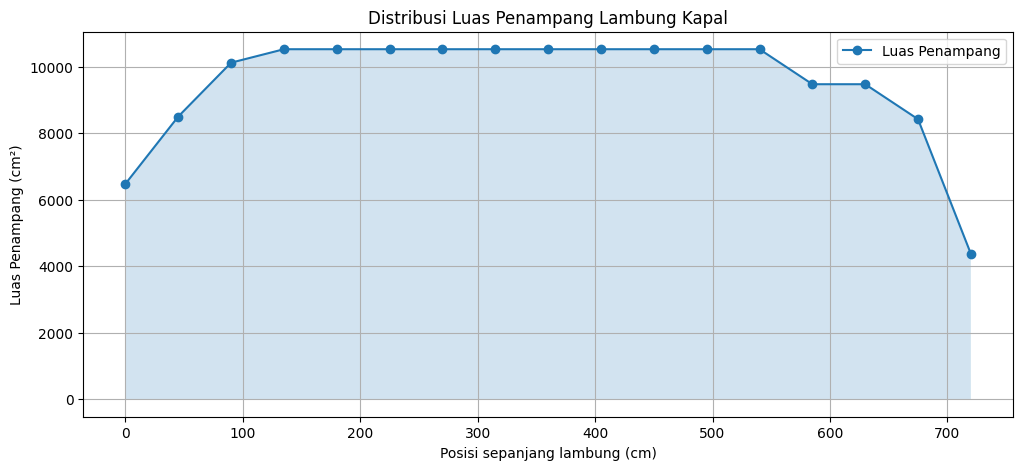

In [7]:
import matplotlib.pyplot as plt

# Posisi setiap stasiun
x = np.arange(0, len(A) * h, h)

plt.figure(figsize=(12, 5))

# Garis luas penampang
plt.plot(x, A, marker='o', label='Luas Penampang')

# Mengarsir area di bawah kurva
plt.fill_between(x, A, alpha=0.2)

plt.xlabel('Posisi sepanjang lambung (cm)')
plt.ylabel('Luas Penampang (cm²)')
plt.title('Distribusi Luas Penampang Lambung Kapal')
plt.grid(True)
plt.legend()

plt.show()

Visualisasi ini menunjukkan perubahan luas penampang dari stasiun awal sampai akhir lambung.

# 6. Visualisasi metode Trapesium

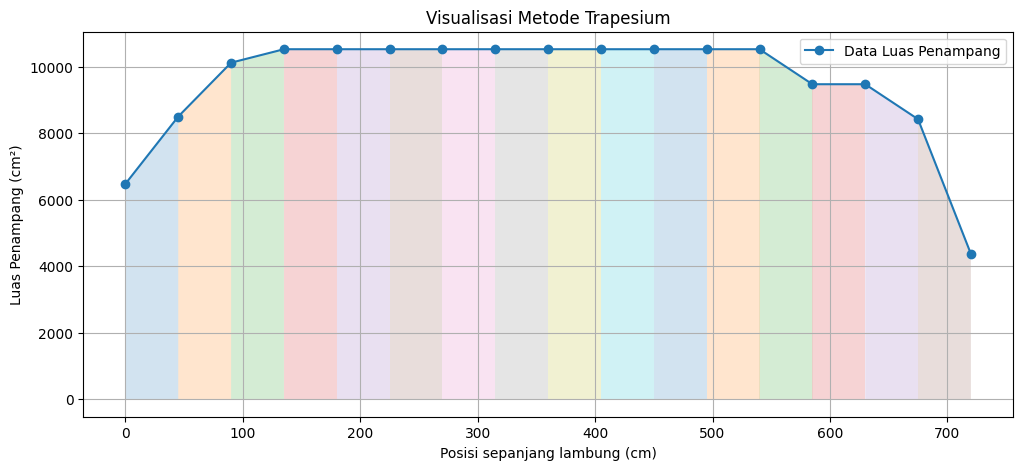

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(x, A, 'o-', label='Data Luas Penampang')

# Membuat bentuk trapesium
for i in range(len(x) - 1):
    plt.fill(
        [x[i], x[i], x[i+1], x[i+1]],
        [0, A[i], A[i+1], 0],
        alpha=0.2
    )

plt.xlabel('Posisi sepanjang lambung (cm)')
plt.ylabel('Luas Penampang (cm²)')
plt.title('Visualisasi Metode Trapesium')
plt.grid(True)
plt.legend()

plt.show()

Ini untuk memperlihatkan bahwa luas di bawah kurva didekati menggunakan bentuk trapesium.

# 7. Visualisasi metode Simpson 1/3

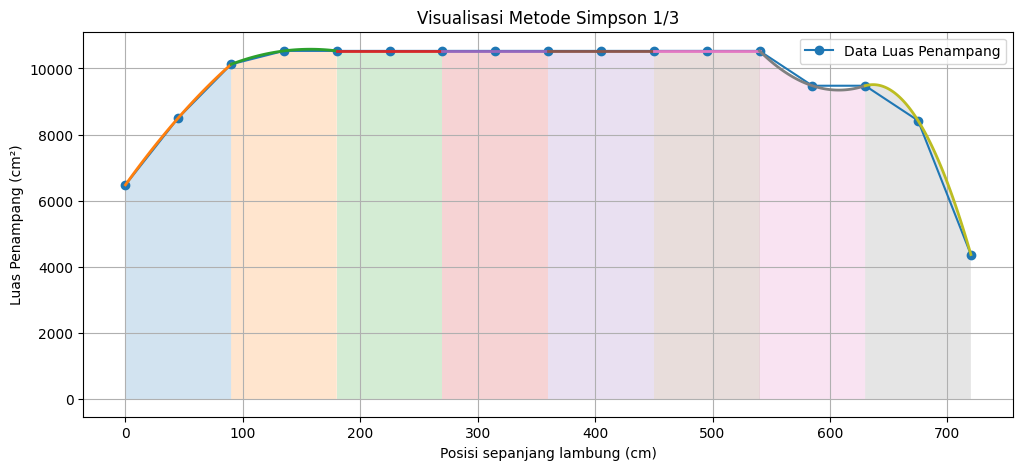

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(x, A, 'o-', label='Data Luas Penampang')

# Membuat kurva parabola Simpson
for i in range(0, len(x) - 2, 2):

    x_local = x[i:i+3]
    A_local = A[i:i+3]

    # Membentuk persamaan parabola
    koef = np.polyfit(x_local, A_local, 2)
    parabola = np.poly1d(koef)

    x_smooth = np.linspace(x_local[0], x_local[-1], 100)
    y_smooth = parabola(x_smooth)

    plt.plot(x_smooth, y_smooth, linewidth=2)
    plt.fill_between(x_smooth, y_smooth, alpha=0.2)

plt.xlabel('Posisi sepanjang lambung (cm)')
plt.ylabel('Luas Penampang (cm²)')
plt.title('Visualisasi Metode Simpson 1/3')
plt.grid(True)
plt.legend()

plt.show()

Pada bagian ini, tiga titik digunakan untuk membentuk pendekatan parabola, sesuai konsep Simpson 1/3

# 8. Visualisasi perbandingan hasil

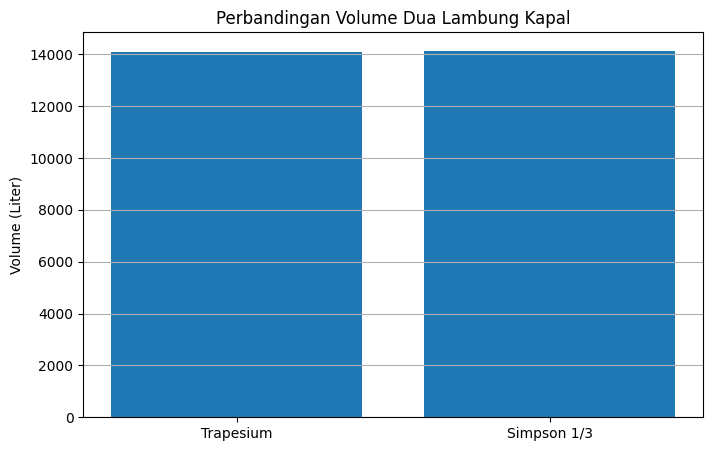

In [10]:
metode = ['Trapesium', 'Simpson 1/3']
volume = [
    volume_trapesium_dua / 1000,
    volume_simpson_dua / 1000
]

plt.figure(figsize=(8, 5))

plt.bar(metode, volume)

plt.ylabel('Volume (Liter)')
plt.title('Perbandingan Volume Dua Lambung Kapal')
plt.grid(axis='y')

plt.show()

Hasilnya akan membandingkan:

Trapesium = 14.106,15 L
Simpson 1/3 = 14.147,46 L

Jadi urutan kode di Colab-mu bisa dibuat: